# ⚡ EV Charging Demand – Machine Learning 

**Goal:** (1) *predict* how much energy (kWh) a charging session will use → **regression**, and
(2) *label* a session as **High** or **Normal** demand → **classification**.

**Before you start**
1. Put `ChargingRecords.csv` in the **same folder** as this notebook.
2. Install the libraries once (in a terminal):
   `pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm imbalanced-learn shap lime streamlit`
3. Run the cells from top to bottom (**Kernel → Restart & Run All**). It takes about 5 minutes.
4. At the end the notebook creates **`ev_models.pkl`**, which the Streamlit app (`app.py`) uses.

| Step | What we do |
|---|---|
| 1 | Load the data |
| 2 | Clean the data |
| 3 | Explore the data (EDA) |
| 4 | Create new columns (feature engineering) |
| 5 | Split into train / test |
| 6 | Regression models |
| 7 | Create the High / Normal column + handle imbalance |
| 8 | Classification models |
| 9 | Explain the models (SHAP & LIME) |
| 10 | Save the models with pickle |

In [1]:
import pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.pipeline import make_pipeline      # a pipeline = scaler + (optional resampler) + model in one object

## Step 1 – Load the data
Each row is **one charging session**. `Demand` is the energy used (kWh) – this is what we want to predict.

In [2]:
df = pd.read_csv("ChargingRecords.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (72856, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), str(7)
memory usage: 12.5 MB


In [4]:
df.describe().round(2)

,UserID,ChargerID,ChargerCompany,ChargerType,Duration,Demand
count,72856.00,72856.00,72856.00,72856.00,72856.00,72856.00
mean,338.16,525.49,0.63,0.21,151.19,17.44
std,553.97,569.54,0.48,0.40,146.43,13.49
min,0.00,1.00,0.00,0.00,-29.00,0.01
25%,0.00,107.00,0.00,0.00,40.00,7.53
50%,62.00,301.00,1.00,0.00,112.00,14.10
75%,407.00,738.00,1.00,0.00,202.00,23.20
max,2501.00,2671.00,1.00,1.00,1573.00,97.00


## Step 2 – Clean the data
We check for missing values and duplicates, turn text dates into real dates, and remove impossible rows.

> ⚠️ The `Duration` column in the file contains mistakes (for example zeros). We **recalculate** it from the start and end times.

In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# text -> real date/time
df["Start"] = pd.to_datetime(df["StartDay"] + " " + df["StartTime"])
df["End"]   = pd.to_datetime(df["EndDay"] + " " + df["EndTime"])
df["Location"] = df["Location"].str.strip().str.lower()

# recalculate Duration (minutes)
new_duration = (df["End"] - df["Start"]).dt.total_seconds() / 60
print("Rows where the stored Duration was wrong:", ((df["Duration"] - new_duration).abs() > 2).sum())
df["Duration"] = new_duration

Missing values: 0


Duplicate rows: 13


Rows where the stored Duration was wrong: 2813


In [6]:
# remove impossible rows: zero/negative duration, longer than 3 days, no energy, or power above 200 kW
df = df[(df["Duration"] > 0) & (df["Duration"] <= 72 * 60) & (df["Demand"] > 0)]
df["Power_kW"] = df["Demand"] / (df["Duration"] / 60)
df = df[df["Power_kW"] <= 200]

df = df.sort_values("Start").reset_index(drop=True)      # oldest -> newest (important for step 5)
print("Rows after cleaning:", len(df))

Rows after cleaning: 72746


## Step 3 – Exploratory Data Analysis (EDA)
Let's look at the data with simple charts. First we add three easy time columns.

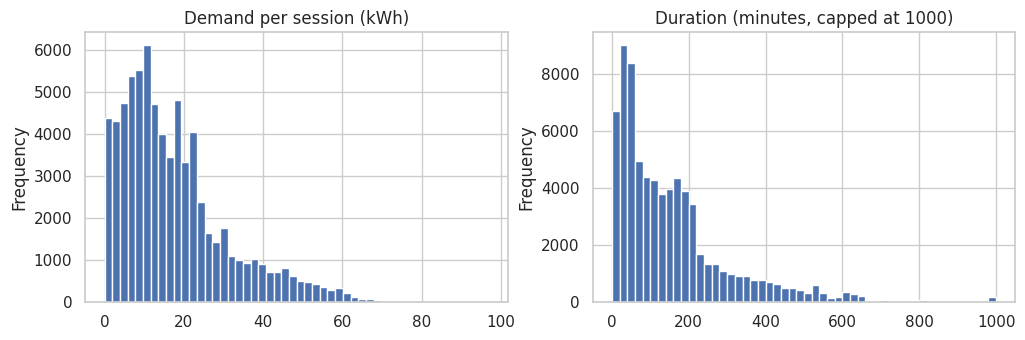

In [7]:
df["Hour"] = df["Start"].dt.hour
df["DayOfWeek"] = df["Start"].dt.dayofweek        # 0 = Monday ... 6 = Sunday
df["Month"] = df["Start"].dt.month

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["Demand"].plot.hist(bins=50, ax=ax[0], title="Demand per session (kWh)")
df["Duration"].clip(upper=1000).plot.hist(bins=50, ax=ax[1], title="Duration (minutes, capped at 1000)")
plt.show()

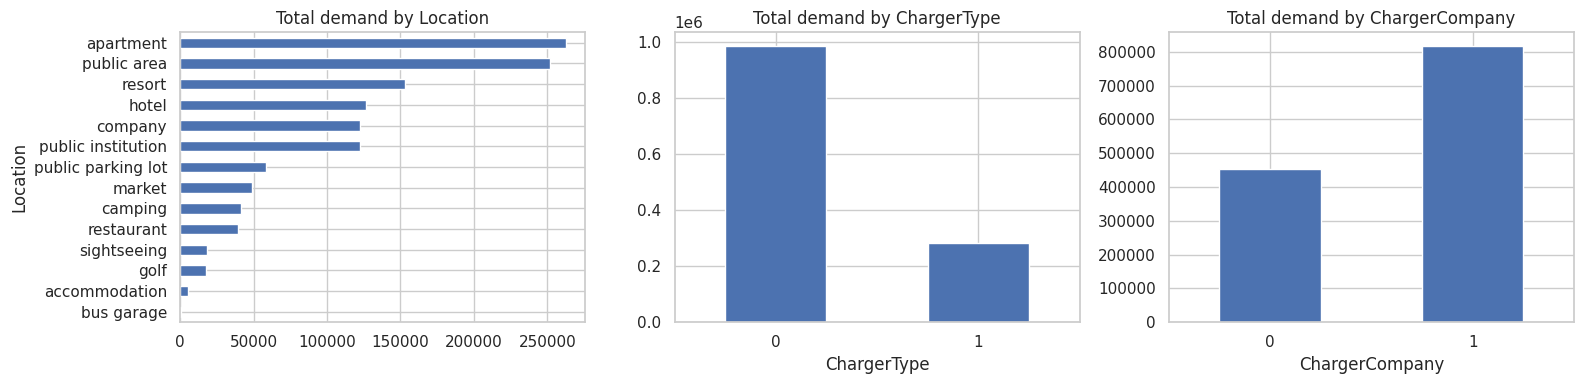

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("Location")["Demand"].sum().sort_values().plot.barh(ax=ax[0], title="Total demand by Location")
df.groupby("ChargerType")["Demand"].sum().plot.bar(ax=ax[1], title="Total demand by ChargerType", rot=0)
df.groupby("ChargerCompany")["Demand"].sum().plot.bar(ax=ax[2], title="Total demand by ChargerCompany", rot=0)
plt.tight_layout(); plt.show()

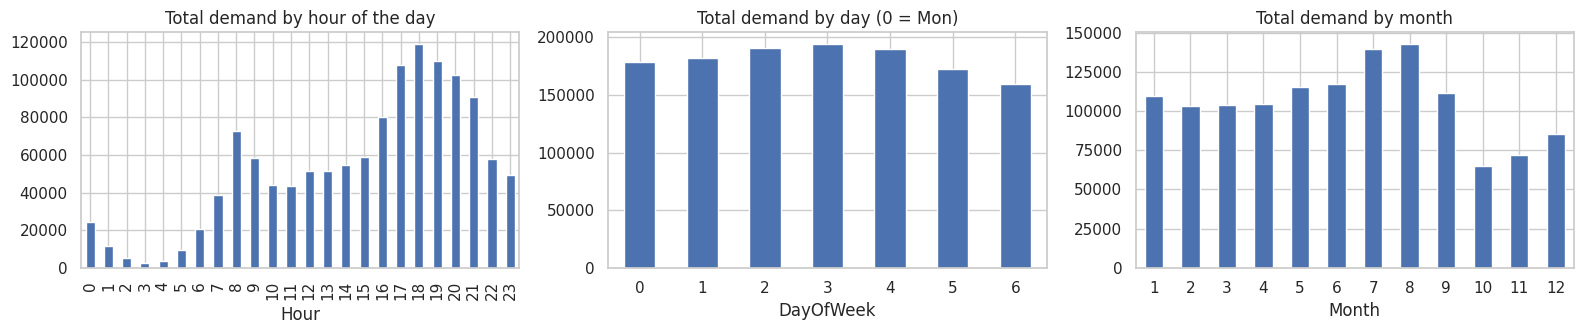

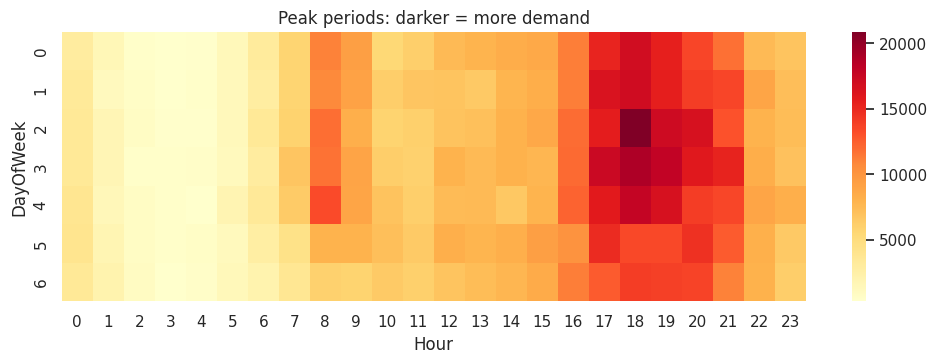

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
df.groupby("Hour")["Demand"].sum().plot.bar(ax=ax[0], title="Total demand by hour of the day")
df.groupby("DayOfWeek")["Demand"].sum().plot.bar(ax=ax[1], title="Total demand by day (0 = Mon)", rot=0)
df.groupby("Month")["Demand"].sum().plot.bar(ax=ax[2], title="Total demand by month", rot=0)
plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 3.5))
sns.heatmap(df.pivot_table(index="DayOfWeek", columns="Hour", values="Demand", aggfunc="sum"), cmap="YlOrRd")
plt.title("Peak periods: darker = more demand"); plt.show()

In [10]:
print("Location with the most total demand :", df.groupby("Location")["Demand"].sum().idxmax())
print("Busiest start hour                  :", df.groupby("Hour")["Demand"].sum().idxmax())
print("Charger type with the most energy   :", df.groupby("ChargerType")["Demand"].sum().idxmax())
print("Average kWh per session by type     :", df.groupby("ChargerType")["Demand"].mean().round(1).to_dict())

Location with the most total demand : apartment
Busiest start hour                  : 18
Charger type with the most energy   : 0
Average kWh per session by type     : {0: 17.1, 1: 18.9}


**What to notice:** demand is concentrated in the evening, a few locations deliver most of the energy, and the two charger
types behave very differently. Also, `Demand` grows with `Duration` – but we will **not** use `Duration` to predict
(see Step 5).

## Step 4 – Create new columns (feature engineering)
Machine-learning models like numbers that describe the situation. We add:
* **Time columns:** `Day`, `IsWeekend`, `TimeOfDay`
* **History columns:** the *average demand of earlier sessions* of the same charger and of the same user.
  (`.shift()` makes sure a session only sees the **past**, never itself.)

`UserID 0` is shared by 43% of sessions – it looks like "guest / unknown", so we give it no user history and mark it with `IsAnonymous`.

In [11]:
df["Day"] = df["Start"].dt.day
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)
df["TimeOfDay"] = np.select([df["Hour"].between(5, 11), df["Hour"].between(12, 16), df["Hour"].between(17, 21)],
                            ["Morning", "Afternoon", "Evening"], default="Night")

# average of the PREVIOUS sessions (shift() hides the current row)
past_mean = lambda col, who: df.groupby(who)[col].transform(lambda s: s.shift().expanding().mean())
df["Charger_prev_mean"]    = past_mean("Demand", "ChargerID")
df["User_prev_mean"]       = past_mean("Demand", "UserID")
df["User_prev_duration"]   = past_mean("Duration", "UserID")
df["Charger_prev_count"]   = df.groupby("ChargerID").cumcount()     # how many sessions before this one
df["User_prev_count"]      = df.groupby("UserID").cumcount()

df["IsAnonymous"] = (df["UserID"] == 0).astype(int)
guest = df["IsAnonymous"] == 1
df.loc[guest, "User_prev_mean"] = np.nan
df.loc[guest, "User_prev_duration"] = np.nan
df.loc[guest, "User_prev_count"] = 0

df[["Start", "Location", "Demand", "TimeOfDay", "Charger_prev_mean", "User_prev_mean", "IsAnonymous"]].tail()

,Start,Location,Demand,TimeOfDay,Charger_prev_mean,User_prev_mean,IsAnonymous
72741,2022-09-30 21:49:59,hotel,6.00,Evening,17.274126,NaN,1
72742,2022-09-30 22:10:38,public parking lot,15.79,Night,17.558621,15.676667,0
72743,2022-09-30 22:31:03,public area,5.83,Night,21.327979,NaN,1
72744,2022-09-30 22:37:45,resort,8.49,Night,17.578818,NaN,0
72745,2022-09-30 23:11:59,public institution,0.10,Night,23.977626,NaN,1


## Step 5 – Train / test split (without cheating)
* **X** = the input columns, **y** = what we predict (`Demand`).
* **Time-based split:** we train on the **oldest 80%** of sessions and test on the **newest 20%** – like predicting the real future.
* **Text → numbers:** `Location` and `TimeOfDay` become 0/1 columns (*one-hot encoding*, `pd.get_dummies`).
* **Data leakage** = giving the model information it would not have in real life. So we **do not use**
  `Duration`, `End` time, `UserID` or `ChargerID` as inputs: duration is only known *after* the session ends.
* Missing values are filled with the **training** averages only.

In [12]:
inputs = ["ChargerCompany", "ChargerType", "Hour", "Day", "Month", "DayOfWeek", "IsWeekend",
          "Charger_prev_mean", "Charger_prev_count", "User_prev_mean", "User_prev_duration",
          "User_prev_count", "IsAnonymous", "Location", "TimeOfDay"]
X = pd.get_dummies(df[inputs], dtype=int)

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = df["Demand"].iloc[:split], df["Demand"].iloc[split:]

fill_values = X_train.mean()                       # learned from training data only
X_train, X_test = X_train.fillna(fill_values), X_test.fillna(fill_values)

print("Train:", X_train.shape, "from", df["Start"].iloc[0].date(), "to", df["Start"].iloc[split - 1].date())
print("Test :", X_test.shape,  "from", df["Start"].iloc[split].date(), "to", df["Start"].iloc[-1].date())

Train: (58196, 31) from 2021-09-30 to 2022-07-30
Test : (14550, 31) from 2022-07-30 to 2022-09-30


## Step 6 – Regression: predict the energy (kWh)
We train six models. Each one is put in a **pipeline**: first `StandardScaler` (puts all numbers on the same scale), then the model.

How to read the scores:
* **MAE** – average mistake in kWh (smaller is better)
* **MSE / RMSE** – like MAE but punishes big mistakes more (smaller is better)
* **R²** – 1 is perfect, 0 is "no better than guessing the average" (bigger is better)

In [13]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree":     DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, max_depth=4, learning_rate=0.08, subsample=0.8, random_state=42),
    "XGBoost":           XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42),
    "LightGBM":          LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=42, verbose=-1),
}

reg_pipes, reg_scores = {}, {}
for name, model in reg_models.items():
    pipe = make_pipeline(StandardScaler(), model).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    reg_pipes[name] = pipe
    reg_scores[name] = {"MAE": mean_absolute_error(y_test, pred), "MSE": mse, "RMSE": mse ** 0.5, "R2": r2_score(y_test, pred)}

reg_results = pd.DataFrame(reg_scores).T.sort_values("R2", ascending=False).round(3)
reg_results

,MAE,MSE,RMSE,R2
LightGBM,8.182,125.975,11.224,0.349
Random Forest,8.191,126.904,11.265,0.344
XGBoost,8.287,127.461,11.290,0.341
Gradient Boosting,8.549,130.399,11.419,0.326
Linear Regression,8.549,132.258,11.500,0.317
Decision Tree,8.514,136.778,11.695,0.293


Best regression model: LightGBM  (R2 = 0.349, average mistake = 8.182 kWh)
Guessing the average every time would be wrong by 10.9 kWh on average.


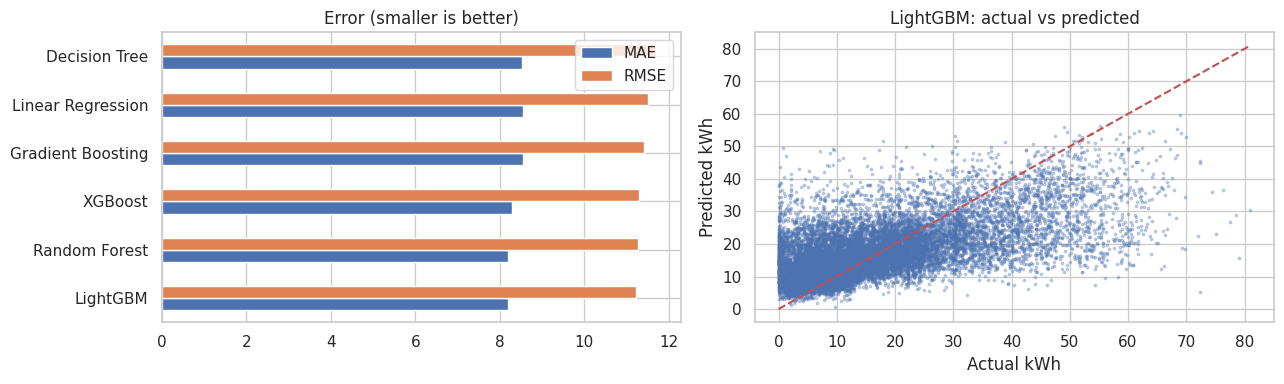

In [14]:
best_reg = reg_results["R2"].idxmax()
reg_pred = reg_pipes[best_reg].predict(X_test)
print(f"Best regression model: {best_reg}  (R2 = {reg_results.loc[best_reg, 'R2']}, average mistake = {reg_results.loc[best_reg, 'MAE']} kWh)")
print(f"Guessing the average every time would be wrong by {mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):.1f} kWh on average.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
reg_results[["MAE", "RMSE"]].plot.barh(ax=ax[0], title="Error (smaller is better)")
ax[1].scatter(y_test, reg_pred, s=3, alpha=0.3); ax[1].plot([0, y_test.max()], [0, y_test.max()], "r--")
ax[1].set(xlabel="Actual kWh", ylabel="Predicted kWh", title=f"{best_reg}: actual vs predicted")
plt.tight_layout(); plt.show()

### Why we left `Duration` out
Energy ≈ power × time, so if we **cheat** and give the model the duration, it looks much better.
But in real life we do not know the duration when the car plugs in, so such a model could not be used.

In [15]:
with_duration = LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=42, verbose=-1)
with_duration.fit(X_train.assign(Duration=df["Duration"].iloc[:split]), y_train)
r2_cheat = r2_score(y_test, with_duration.predict(X_test.assign(Duration=df["Duration"].iloc[split:])))
print(f"R2 WITHOUT duration (honest): {reg_results.loc['LightGBM', 'R2']}")
print(f"R2 WITH duration (cheating) : {r2_cheat:.3f}   <- looks great, but can't be used in real life")

R2 WITHOUT duration (honest): 0.349
R2 WITH duration (cheating) : 0.803   <- looks great, but can't be used in real life


## Step 7 – Create the High / Normal column (classification target)
We compare every session with the **average (mean) demand of the training data**:
* `Demand ≥ mean` → **High**
* `Demand < mean` → **Normal**

Then we check if the two classes are balanced. If one class is much smaller, the model may ignore it.

Mean demand (training data) = 17.37 kWh
DemandLevel
Normal    42476
High      30270
Name: count, dtype: int64
DemandLevel
Normal    58.4 %
High      41.6 %
Name: proportion, dtype: str


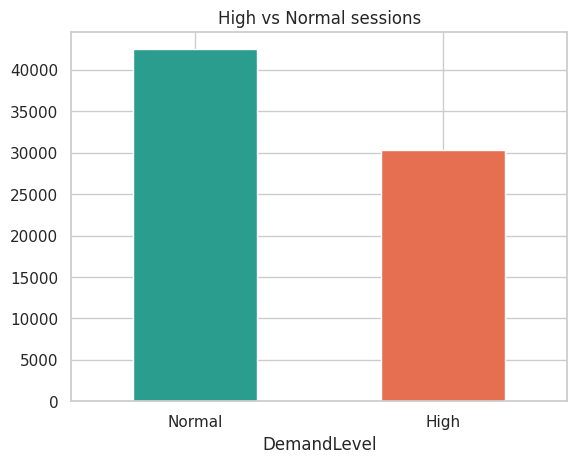

In [16]:
mean_demand = y_train.mean()
df["DemandLevel"] = np.where(df["Demand"] >= mean_demand, "High", "Normal")      # the new column
print(f"Mean demand (training data) = {mean_demand:.2f} kWh")

y_train_c = (df["DemandLevel"].iloc[:split] == "High").astype(int)     # High = 1, Normal = 0
y_test_c  = (df["DemandLevel"].iloc[split:] == "High").astype(int)

print(df["DemandLevel"].value_counts())
print((df["DemandLevel"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")
df["DemandLevel"].value_counts().plot.bar(rot=0, color=["#2a9d8f", "#e76f51"], title="High vs Normal sessions"); plt.show()

The classes are **not equal** (High is the smaller group). We can fix this by **oversampling** the training data only (never the test data):
* **Random Oversampling** – copies existing High rows
* **SMOTE** – creates *new* High rows between similar ones
* **ADASYN** – like SMOTE, but focuses on the hard-to-learn rows

We test each on one quick model (LightGBM) and keep the best by **F1-score** (a balance of precision and recall).

In [17]:
samplers = {"None": None, "Random Oversampling": RandomOverSampler(random_state=42),
            "SMOTE": SMOTE(random_state=42), "ADASYN": ADASYN(random_state=42)}

imbalance_scores = {}
for name, sampler in samplers.items():
    steps = [StandardScaler()] + ([sampler] if sampler else []) + [LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)]
    pipe = make_pipeline(*steps).fit(X_train, y_train_c)
    pred = pipe.predict(X_test)
    imbalance_scores[name] = {"Precision": precision_score(y_test_c, pred), "Recall": recall_score(y_test_c, pred),
                              "F1": f1_score(y_test_c, pred), "ROC_AUC": roc_auc_score(y_test_c, pipe.predict_proba(X_test)[:, 1])}

imbalance_results = pd.DataFrame(imbalance_scores).T.round(3)
best_sampler = imbalance_results["F1"].idxmax()
sampler = samplers[best_sampler]
print("Technique chosen:", best_sampler)
imbalance_results

Technique chosen: ADASYN


,Precision,Recall,F1,ROC_AUC
None,0.671,0.692,0.681,0.813
Random Oversampling,0.637,0.772,0.698,0.812
SMOTE,0.636,0.774,0.698,0.811
ADASYN,0.620,0.810,0.702,0.810


## Step 8 – Classification: predict High or Normal
Seven models, all trained with the technique chosen above. Scores:
* **Accuracy** – % of correct answers
* **Precision** – when the model says *High*, how often is it right?
* **Recall** – of all real *High* sessions, how many did we find?
* **F1** – balance of precision and recall
* **ROC-AUC** – how well the model separates the two classes (0.5 = random, 1 = perfect)

*(SVM is slow, so it learns from a random sample of 10,000 rows.)*

In [18]:
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=9, min_samples_leaf=20, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "SVM":                 SVC(),
    "XGBoost":             XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42),
    "LightGBM":            LGBMClassifier(n_estimators=400, learning_rate=0.05, random_state=42, verbose=-1),
}

clf_pipes, clf_scores, clf_preds = {}, {}, {}
for name, model in clf_models.items():
    pipe = make_pipeline(*([StandardScaler()] + ([sampler] if sampler else []) + [model]))
    if name == "SVM":
        rows = X_train.sample(10000, random_state=42).index
        pipe.fit(X_train.loc[rows], y_train_c.loc[rows])
    else:
        pipe.fit(X_train, y_train_c)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)
    clf_pipes[name], clf_preds[name] = pipe, pred
    clf_scores[name] = {"Accuracy": accuracy_score(y_test_c, pred), "Precision": precision_score(y_test_c, pred),
                        "Recall": recall_score(y_test_c, pred), "F1": f1_score(y_test_c, pred), "ROC_AUC": roc_auc_score(y_test_c, prob)}

clf_results = pd.DataFrame(clf_scores).T.sort_values("F1", ascending=False).round(3)
clf_results

,Accuracy,Precision,Recall,F1,ROC_AUC
XGBoost,0.711,0.612,0.826,0.703,0.811
Random Forest,0.724,0.634,0.787,0.702,0.813
LightGBM,0.716,0.622,0.805,0.702,0.810
SVM,0.700,0.603,0.809,0.691,0.780
Decision Tree,0.701,0.606,0.796,0.688,0.789
KNN,0.693,0.598,0.783,0.678,0.777
Logistic Regression,0.704,0.619,0.742,0.675,0.790


Best classification model: XGBoost  (F1 = 0.703, ROC-AUC = 0.811)


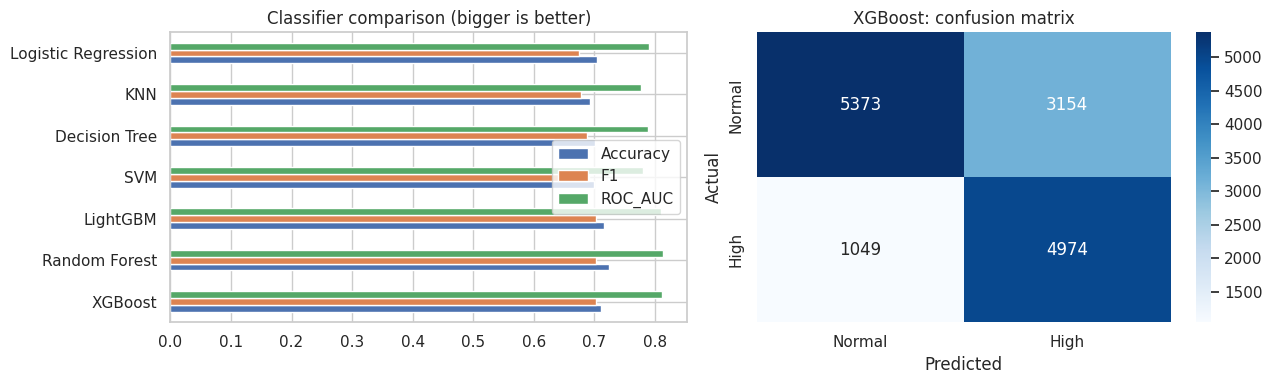

In [19]:
best_clf = clf_results["F1"].idxmax()
print(f"Best classification model: {best_clf}  (F1 = {clf_results.loc[best_clf, 'F1']}, ROC-AUC = {clf_results.loc[best_clf, 'ROC_AUC']})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
clf_results[["Accuracy", "F1", "ROC_AUC"]].plot.barh(ax=ax[0], title="Classifier comparison (bigger is better)")
sns.heatmap(confusion_matrix(y_test_c, clf_preds[best_clf]), annot=True, fmt="d", cmap="Blues", ax=ax[1],
            xticklabels=["Normal", "High"], yticklabels=["Normal", "High"])
ax[1].set(xlabel="Predicted", ylabel="Actual", title=f"{best_clf}: confusion matrix")
plt.tight_layout(); plt.show()

## Step 9 – Why does the model predict what it predicts? (Explainability)
* **Feature importance** – which columns the model uses most.
* **SHAP** – shows how each column pushes a prediction **up** (red = high value of the column) or **down**.
* **LIME** – explains **one single session**.

*(SHAP and LIME here work for tree-based models such as Random Forest, XGBoost or LightGBM – the usual winners.)*

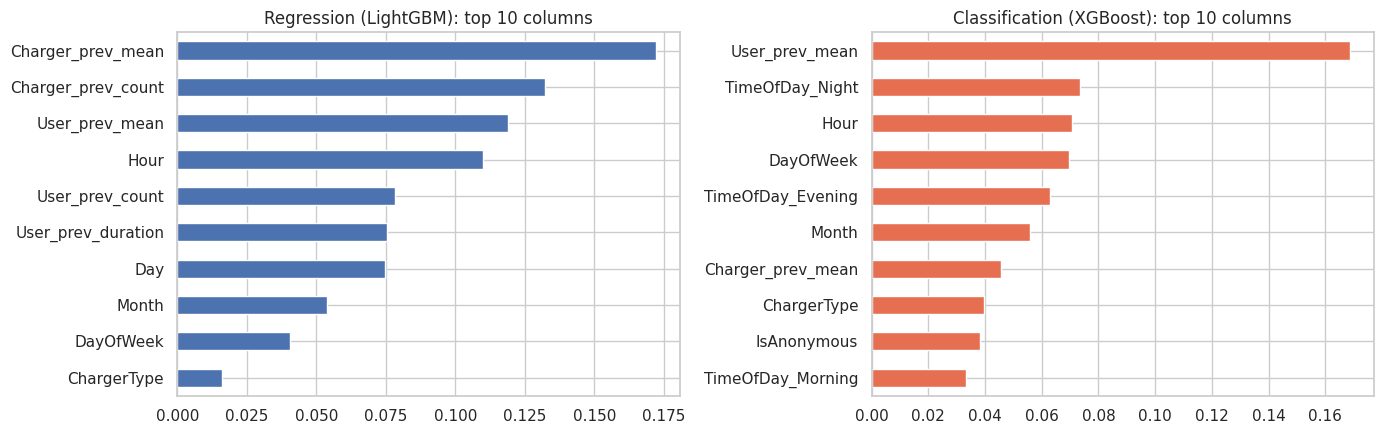

In [20]:
import shap
from lime.lime_tabular import LimeTabularExplainer

reg_pipe, clf_pipe = reg_pipes[best_reg], clf_pipes[best_clf]
reg_model, clf_model = reg_pipe[-1], clf_pipe[-1]           # the model inside each pipeline

reg_importance = pd.Series(reg_model.feature_importances_, index=X.columns).sort_values(ascending=False)
reg_importance = reg_importance / reg_importance.sum()           # as shares that add up to 1
clf_importance = pd.Series(clf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
reg_importance.head(10)[::-1].plot.barh(ax=ax[0], title=f"Regression ({best_reg}): top 10 columns")
clf_importance.head(10)[::-1].plot.barh(ax=ax[1], title=f"Classification ({best_clf}): top 10 columns", color="#e76f51")
plt.tight_layout(); plt.show()

### SHAP – regression model

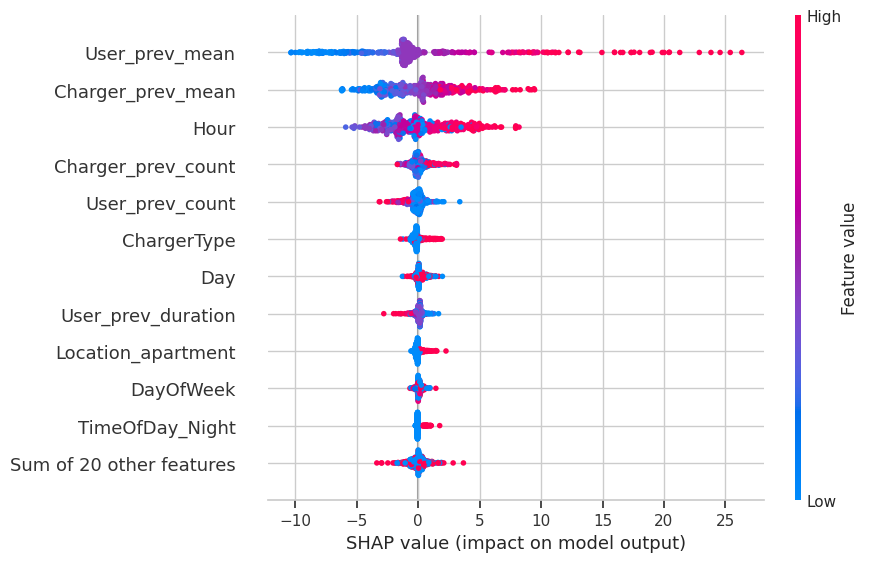

In [21]:
Xs_reg = pd.DataFrame(reg_pipe[0].transform(X_test.iloc[:500]), columns=X.columns)    # 500 test rows (scaled)
sv_reg = shap.TreeExplainer(reg_model)(Xs_reg, check_additivity=False)
shap.plots.beeswarm(sv_reg, max_display=12)

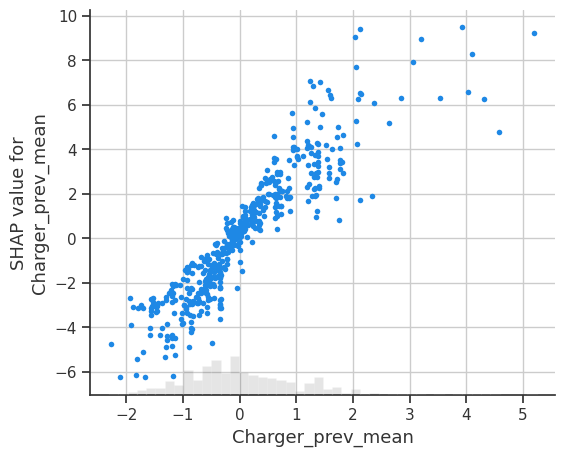

In [22]:
shap.plots.scatter(sv_reg[:, reg_importance.index[0]])      # dependence plot of the most important column

### SHAP – classification model

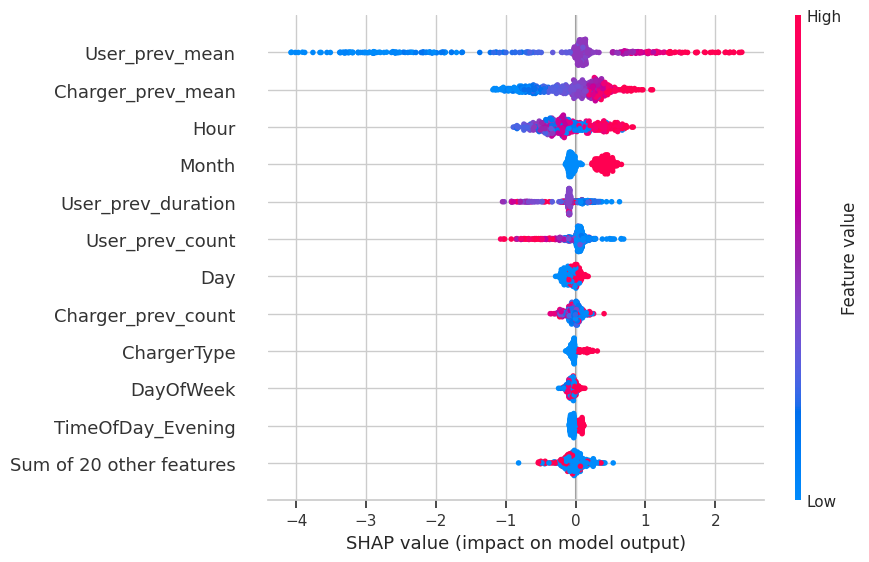

In [23]:
Xs_clf = pd.DataFrame(clf_pipe[0].transform(X_test.iloc[:500]), columns=X.columns)
sv_clf = shap.TreeExplainer(clf_model)(Xs_clf, check_additivity=False)
if sv_clf.values.ndim == 3:            # some models return one set of values per class -> keep the "High" class
    sv_clf = sv_clf[:, :, 1]
shap.plots.beeswarm(sv_clf, max_display=12)

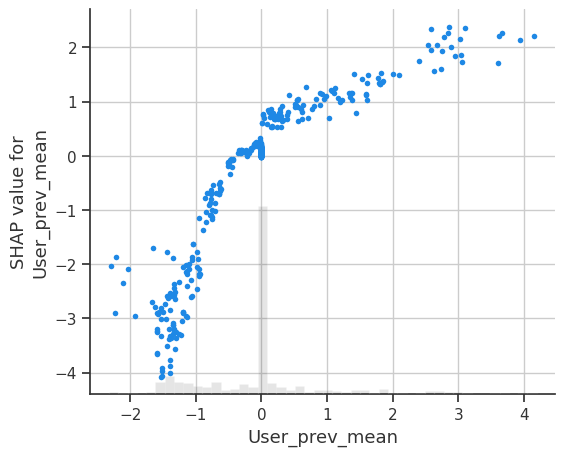

In [24]:
shap.plots.scatter(sv_clf[:, clf_importance.index[0]])

### LIME – explain one session

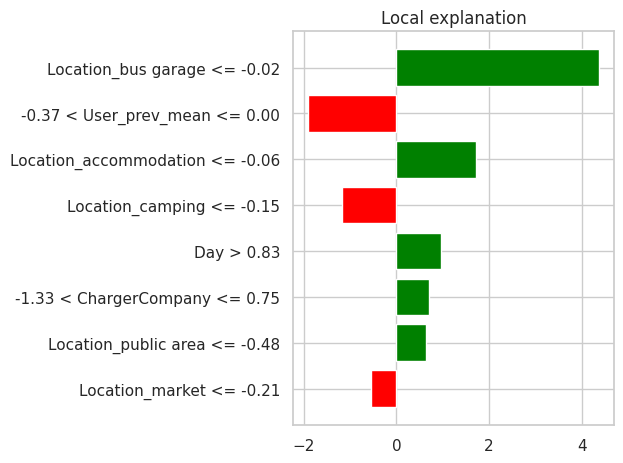

Predicted kWh: 19.9 | Actual kWh: 10.7


In [25]:
train_scaled = reg_pipe[0].transform(X_train)
lime_reg = LimeTabularExplainer(train_scaled, feature_names=list(X.columns), mode="regression")
exp = lime_reg.explain_instance(Xs_reg.values[0], reg_model.predict, num_features=8)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()
print("Predicted kWh:", round(reg_model.predict(Xs_reg.values[:1])[0], 1), "| Actual kWh:", round(y_test.iloc[0], 1))

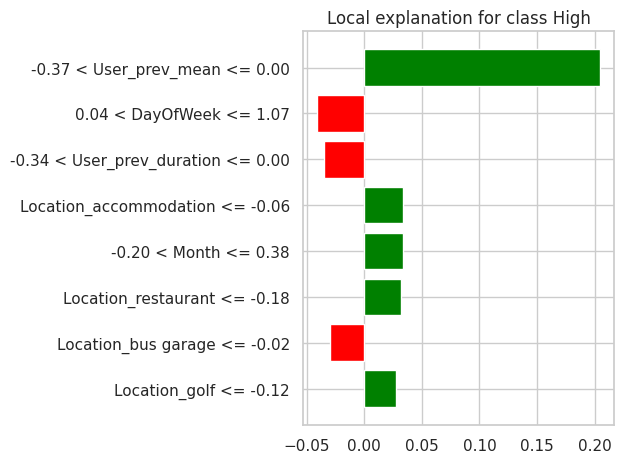

In [26]:
lime_clf = LimeTabularExplainer(clf_pipe[0].transform(X_train), feature_names=list(X.columns), mode="classification",
                                class_names=["Normal", "High"])
exp = lime_clf.explain_instance(Xs_clf.values[0], clf_model.predict_proba, num_features=8)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()

**Typical finding:** the *average demand of the user's and the charger's earlier sessions* are the strongest drivers,
followed by the *time of day*. People tend to charge the same amount as they did before.

## Step 10 – Save everything with pickle
**Pickling** saves Python objects (trained models, tables, data) into one file so we can load them later
**without retraining**. The Streamlit app reads this file.

In [27]:
saved = {
    "reg_model": reg_pipes[best_reg], "reg_name": best_reg, "reg_results": reg_results,
    "reg_importance": reg_importance.head(10), "test_actual": y_test.values, "test_pred": reg_pred,
    "clf_model": clf_pipes[best_clf], "clf_name": best_clf, "clf_results": clf_results,
    "clf_importance": clf_importance.head(10), "imbalance_results": imbalance_results, "sampler_used": best_sampler,
    "columns": list(X.columns), "fill_values": fill_values, "mean_demand": mean_demand,
    "eda_data": df[["Start", "UserID", "ChargerID", "ChargerCompany", "ChargerType", "Location",
                    "Demand", "Duration", "Hour", "DayOfWeek", "Month", "DemandLevel"]],
}
with open("ev_models.pkl", "wb") as f:
    pickle.dump(saved, f)
print("Saved ev_models.pkl")

Saved ev_models.pkl


Let's prove it works: load the file and predict for one test session.

In [28]:
with open("ev_models.pkl", "rb") as f:
    loaded = pickle.load(f)

one_session = X_test.iloc[[0]]
print("Predicted energy :", round(loaded["reg_model"].predict(one_session)[0], 1), "kWh   (actual:", round(y_test.iloc[0], 1), "kWh)")
print("Chance of 'High' :", round(loaded["clf_model"].predict_proba(one_session)[0, 1] * 100), "%   (actual:", df["DemandLevel"].iloc[split], ")")

Predicted energy : 19.9 kWh   (actual: 10.7 kWh)
Chance of 'High' : 62 %   (actual: Normal )


## ✅ Done – run the dashboard
Open a terminal in this folder and run:

```
streamlit run app.py
```